In [26]:
from pathlib import Path
import pandas as pd

In [27]:
DATA_DIR = next(Path(r"C:\Users\ADMIN\Downloads").rglob("olist_orders_dataset.csv")).parent
print("Found data in:", DATA_DIR)

files = {"orders": "olist_orders_dataset.csv", "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv", "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv", "products": "olist_products_dataset.csv", "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv", "category_translation": "product_category_name_translation.csv",}

bronze = {name: pd.read_csv(DATA_DIR / fname) for name, fname in files.items()}

audit = pd.DataFrame([{"table": name, "rows": df.shape[0], "columns": df.shape[1], "missing_cells": int(df.isna().sum().sum()),}
    for name, df in bronze.items()])

display(audit)

Found data in: C:\Users\ADMIN\Downloads\olist_project


,table,rows,columns,missing_cells
0,orders,99441,8,4908
1,order_items,112650,7,0
2,payments,103886,5,0
3,reviews,99224,7,145903
4,customers,99441,5,0
5,products,32951,9,2448
6,sellers,3095,4,0
7,geolocation,1000163,5,0
8,category_translation,71,2,0


In [28]:
for name, df in bronze.items():
    nulls = df.isna().sum()
    nulls = nulls[nulls > 0]
    dups = df.duplicated().sum()
    print(f"=== {name} ({df.shape[0]:,} rows) | exact duplicates: {dups:,} ===")
    if len(nulls) > 0:
        print(nulls.to_dict())
    else:
        print("No missing values")
    print()

=== orders (99,441 rows) | exact duplicates: 0 ===
{'order_approved_at': 160, 'order_delivered_carrier_date': 1783, 'order_delivered_customer_date': 2965}

=== order_items (112,650 rows) | exact duplicates: 0 ===
No missing values

=== payments (103,886 rows) | exact duplicates: 0 ===
No missing values

=== reviews (99,224 rows) | exact duplicates: 0 ===
{'review_comment_title': 87656, 'review_comment_message': 58247}

=== customers (99,441 rows) | exact duplicates: 0 ===
No missing values

=== products (32,951 rows) | exact duplicates: 0 ===
{'product_category_name': 610, 'product_name_lenght': 610, 'product_description_lenght': 610, 'product_photos_qty': 610, 'product_weight_g': 2, 'product_length_cm': 2, 'product_height_cm': 2, 'product_width_cm': 2}

=== sellers (3,095 rows) | exact duplicates: 0 ===
No missing values

=== geolocation (1,000,163 rows) | exact duplicates: 261,831 ===
No missing values

=== category_translation (71 rows) | exact duplicates: 0 ===
No missing values



In [29]:
orders = bronze["orders"].copy()

date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date",]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

orders["delivery_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]).dt.total_seconds() / 86400
orders["is_late"] = (orders["order_delivered_customer_date"] > orders["order_estimated_delivery_date"])

invalid_delivery = (orders["delivery_days"] < 0).sum()
orders = orders[orders["delivery_days"].isna() | (orders["delivery_days"] >= 0)].copy()

print("Negative delivery_days removed:", invalid_delivery)
print("\nOrder status counts:")
print(orders["order_status"].value_counts())

Negative delivery_days removed: 0

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [30]:
products = bronze["products"].merge(bronze["category_translation"], on="product_category_name", how="left")

products["product_category_name"] = products["product_category_name"].fillna("unknown")
products["product_category_name_english"] = products["product_category_name_english"].fillna(products["product_category_name"])

num_cols = ["product_name_lenght", "product_description_lenght", "product_photos_qty", "product_weight_g",
    "product_length_cm", "product_height_cm", "product_width_cm",]
for col in num_cols:
    products[col] = products[col].fillna(products[col].median())

print("Products rows:", len(products))
print("Remaining missing cells in products:", int(products.isna().sum().sum()))
print("Top 5 English categories:")
print(products["product_category_name_english"].value_counts().head(5))

Products rows: 32951
Remaining missing cells in products: 0
Top 5 English categories:
product_category_name_english
bed_bath_table     3029
sports_leisure     2867
furniture_decor    2657
health_beauty      2444
housewares         2335
Name: count, dtype: int64


In [31]:
geo = bronze["geolocation"].copy()
geo_brazil = geo[geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-75, -32)].copy()

geo_brazil["geolocation_city"] = (geo_brazil["geolocation_city"].astype(str).str.strip().str.lower())
geo_brazil["geolocation_state"] = (geo_brazil["geolocation_state"].astype(str).str.strip().str.upper())

geolocation = (geo_brazil.groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean"), city=("geolocation_city", "first"), state=("geolocation_state", "first"),))

customers = bronze["customers"].drop_duplicates(subset=["customer_id"]).copy()
customers["customer_city"] = customers["customer_city"].astype(str).str.strip().str.lower()
customers["customer_state"] = customers["customer_state"].astype(str).str.strip().str.upper()

sellers = bronze["sellers"].drop_duplicates(subset=["seller_id"]).copy()
sellers["seller_city"] = sellers["seller_city"].astype(str).str.strip().str.lower()
sellers["seller_state"] = sellers["seller_state"].astype(str).str.strip().str.upper()

reviews = bronze["reviews"].drop_duplicates(subset=["review_id"]).copy()
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

print("Geolocation outliers removed:", len(geo) - len(geo_brazil))
print("Geolocation rows after zip deduplication:", len(geolocation))
print("Customers:", len(customers), "| Sellers:", len(sellers), "| Reviews:", len(reviews))

Geolocation outliers removed: 31
Geolocation rows after zip deduplication: 19011
Customers: 99441 | Sellers: 3095 | Reviews: 98410


In [32]:
order_items = bronze["order_items"].drop_duplicates().copy()
order_items["shipping_limit_date"] = pd.to_datetime(order_items["shipping_limit_date"])
order_items["total_item_value"] = order_items["price"] + order_items["freight_value"]

payments = bronze["payments"].drop_duplicates().copy()

silver = {
    "fact_orders": orders,
    "fact_order_items": order_items,
    "fact_payments": payments,
    "fact_reviews": reviews,
    "dim_customers": customers,
    "dim_products": products.drop_duplicates(subset=["product_id"]),
    "dim_sellers": sellers,
    "dim_geolocation": geolocation,}

assert (silver["fact_order_items"]["price"] >= 0).all()
assert (silver["fact_order_items"]["freight_value"] >= 0).all()
assert (silver["fact_payments"]["payment_value"] >= 0).all()
assert silver["fact_reviews"]["review_score"].between(1, 5).all()
assert silver["fact_orders"]["customer_id"].isin(silver["dim_customers"]["customer_id"]).all()
assert silver["fact_order_items"]["order_id"].isin(silver["fact_orders"]["order_id"]).all()
assert silver["fact_order_items"]["product_id"].isin(silver["dim_products"]["product_id"]).all()
assert silver["fact_order_items"]["seller_id"].isin(silver["dim_sellers"]["seller_id"]).all()

silver_summary = pd.DataFrame([{"silver_table": name, "rows": df.shape[0], "columns": df.shape[1]}
    for name, df in silver.items()])
print("All Data Quality & Referential Integrity checks PASSED!")
display(silver_summary)

All Data Quality & Referential Integrity checks PASSED!


,silver_table,rows,columns
0,fact_orders,99441,10
1,fact_order_items,112650,8
2,fact_payments,103886,5
3,fact_reviews,98410,7
4,dim_customers,99441,5
5,dim_products,32951,10
6,dim_sellers,3095,4
7,dim_geolocation,19011,5


In [36]:
import sqlite3

conn = sqlite3.connect("olist_warehouse.db")

for table_name, df in silver.items():
    df_sql = df.copy()
    for col in df_sql.select_dtypes(include=["datetime64[ns]"]).columns:
        df_sql[col] = df_sql[col].dt.strftime("%Y-%m-%d %H:%M:%S")
    df_sql.to_sql(table_name, conn, if_exists="replace", index=False)

tables_in_db = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;", conn)
print("Loaded into olist_warehouse.db:")
display(tables_in_db)

Loaded into olist_warehouse.db:


,name
0,dim_customers
1,dim_geolocation
2,dim_products
3,dim_sellers
4,fact_order_items
5,fact_orders
6,fact_payments
7,fact_reviews
8,gold_customer_rfm
9,gold_delivery_reviews


,order_month,total_orders,total_revenue_brl,avg_item_value_brl
13,2017-11,7289,1153364.20,136.09
14,2017-12,5513,843078.29,136.27
15,2018-01,7069,1077887.46,134.12
16,2018-02,6555,966168.41,128.51
17,2018-03,7003,1120598.24,139.78
18,2018-04,6798,1132878.93,144.74
19,2018-05,6749,1128774.52,144.53
20,2018-06,6099,1011978.29,144.36
21,2018-07,6159,1027807.28,147.61
22,2018-08,6351,985491.64,137.99


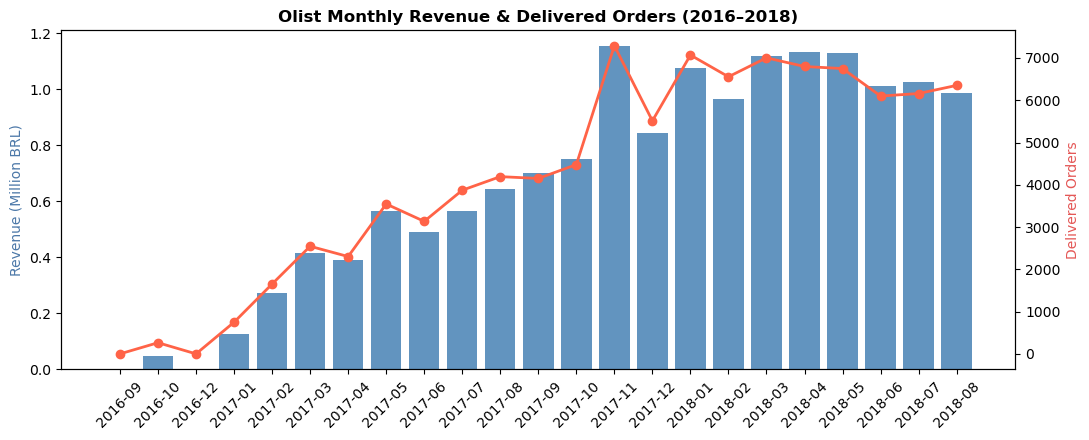

In [37]:
from pathlib import Path
import matplotlib.pyplot as plt

Path("images").mkdir(exist_ok=True)

conn.execute("DROP TABLE IF EXISTS gold_monthly_revenue;")
conn.execute("""
CREATE TABLE gold_monthly_revenue AS
SELECT
    SUBSTR(o.order_purchase_timestamp, 1, 7) AS order_month,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(oi.total_item_value), 2) AS total_revenue_brl,
    ROUND(AVG(oi.total_item_value), 2) AS avg_item_value_brl
FROM fact_orders o
JOIN fact_order_items oi ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY order_month
ORDER BY order_month;
""")

monthly_rev = pd.read_sql_query("SELECT * FROM gold_monthly_revenue;", conn)
display(monthly_rev.tail(10))

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(monthly_rev["order_month"], monthly_rev["total_revenue_brl"] / 1e6, color="steelblue", alpha=0.85)
ax1.set_ylabel("Revenue (Million BRL)", color="#4c78a8")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(monthly_rev["order_month"], monthly_rev["total_orders"], color="tomato", marker="o", linewidth=2)
ax2.set_ylabel("Delivered Orders", color="#e45756")

plt.title("Olist Monthly Revenue & Delivered Orders (2016–2018)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("images/01_monthly_revenue.png", dpi=300, bbox_inches="tight")
plt.show()

,category,total_orders,total_revenue_brl
0,health_beauty,8647,1412089.53
1,watches_gifts,5495,1264333.12
2,bed_bath_table,9272,1225209.26
3,sports_leisure,7530,1118256.91
4,computers_accessories,6530,1032723.77
5,furniture_decor,6307,880329.92
6,housewares,5743,758392.25
7,cool_stuff,3559,691680.89
8,auto,3810,669454.75
9,garden_tools,3448,567145.68


,payment_type,payment_count,total_value_brl
0,credit_card,76795,12542084.19
1,boleto,19784,2869361.27
2,voucher,5775,379436.87
3,debit_card,1529,217989.79
4,not_defined,3,0.00


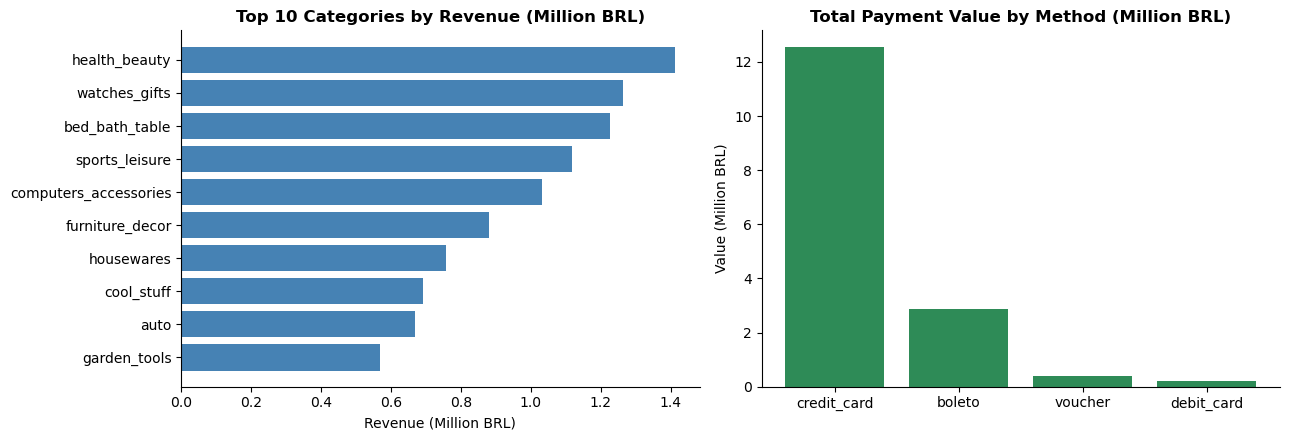

In [38]:
conn.execute("DROP TABLE IF EXISTS gold_top_categories;")
conn.execute("""
CREATE TABLE gold_top_categories AS
SELECT
    p.product_category_name_english AS category,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    ROUND(SUM(oi.total_item_value), 2) AS total_revenue_brl
FROM fact_order_items oi
JOIN fact_orders o ON oi.order_id = o.order_id
JOIN dim_products p ON oi.product_id = p.product_id
WHERE o.order_status = 'delivered'
GROUP BY p.product_category_name_english
ORDER BY total_revenue_brl DESC;
""")

top_cats = pd.read_sql_query("SELECT * FROM gold_top_categories LIMIT 10;", conn)
payment_mix = pd.read_sql_query("""
SELECT
    payment_type,
    COUNT(*) AS payment_count,
    ROUND(SUM(payment_value), 2) AS total_value_brl
FROM fact_payments
GROUP BY payment_type
ORDER BY total_value_brl DESC;
""", conn)

display(top_cats)
display(payment_mix)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

cats_plot = top_cats.sort_values("total_revenue_brl", ascending=True)
ax1.barh(cats_plot["category"], cats_plot["total_revenue_brl"] / 1e6, color="steelblue")
ax1.set_title("Top 10 Categories by Revenue (Million BRL)", fontweight="bold")
ax1.set_xlabel("Revenue (Million BRL)")
ax1.spines[["top", "right"]].set_visible(False)

pay_plot = payment_mix[payment_mix["payment_type"] != "not_defined"]
ax2.bar(pay_plot["payment_type"], pay_plot["total_value_brl"] / 1e6, color="seagreen")
ax2.set_title("Total Payment Value by Method (Million BRL)", fontweight="bold")
ax2.set_ylabel("Value (Million BRL)")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("images/02_categories_and_payments.png", dpi=300, bbox_inches="tight")
plt.show()

,delivery_status,total_orders,avg_delivery_days,avg_review_score,share_%
0,Late,7613,31.39,2.57,7.98
1,On Time,87751,10.88,4.30,92.02


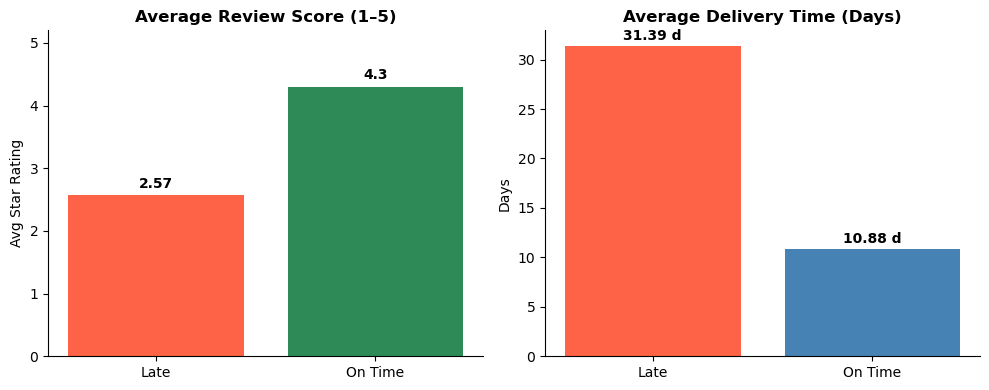

In [39]:
conn.execute("DROP TABLE IF EXISTS gold_delivery_reviews;")
conn.execute("""
CREATE TABLE gold_delivery_reviews AS
SELECT
    CASE WHEN o.is_late = 1 THEN 'Late' ELSE 'On Time' END AS delivery_status,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(AVG(o.delivery_days), 2) AS avg_delivery_days,
    ROUND(AVG(r.review_score), 2) AS avg_review_score
FROM fact_orders o
JOIN fact_reviews r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.delivery_days IS NOT NULL
GROUP BY delivery_status;
""")

sla = pd.read_sql_query("SELECT * FROM gold_delivery_reviews;", conn)
sla["share_%"] = (sla["total_orders"] / sla["total_orders"].sum() * 100).round(2)
display(sla)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.bar(sla["delivery_status"], sla["avg_review_score"], color=["tomato", "seagreen"])
ax1.set_ylim(0, 5.2)
ax1.set_title("Average Review Score (1–5)", fontweight="bold")
ax1.set_ylabel("Avg Star Rating")
for i, v in enumerate(sla["avg_review_score"]):
    ax1.text(i, v + 0.12, f"{v}", ha="center", fontweight="bold")
ax1.spines[["top", "right"]].set_visible(False)

ax2.bar(sla["delivery_status"], sla["avg_delivery_days"], color=["tomato", "steelblue"])
ax2.set_title("Average Delivery Time (Days)", fontweight="bold")
ax2.set_ylabel("Days")
for i, v in enumerate(sla["avg_delivery_days"]):
    ax2.text(i, v + 0.6, f"{v} d", ha="center", fontweight="bold")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("images/03_delivery_vs_reviews.png", dpi=300, bbox_inches="tight")
plt.show()

Total unique customers: 93,358
Repeat customer rate (>1 order): 3.00%


,customers,avg_spend_brl,share_%
segment,,,
At Risk,34415,162.829430,36.86
Active / Promising,31174,132.085200,33.39
Hibernating / Lost,20591,161.332268,22.06
Recent High-Value,5937,333.249158,6.36
Loyal Repeat,1241,320.613956,1.33


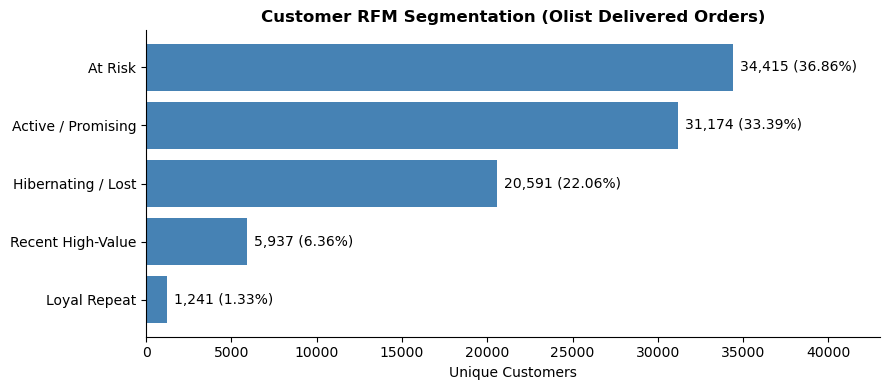

In [40]:
conn.execute("DROP TABLE IF EXISTS gold_customer_rfm;")
conn.execute("""
CREATE TABLE gold_customer_rfm AS
WITH max_dt AS (
    SELECT MAX(order_purchase_timestamp) AS latest_date
    FROM fact_orders
    WHERE order_status = 'delivered'
)
SELECT
    c.customer_unique_id,
    CAST(JULIANDAY((SELECT latest_date FROM max_dt)) - JULIANDAY(MAX(o.order_purchase_timestamp)) AS INT) AS recency_days,
    COUNT(DISTINCT o.order_id) AS frequency,
    ROUND(SUM(oi.total_item_value), 2) AS monetary_brl
FROM fact_orders o
JOIN dim_customers c ON o.customer_id = c.customer_id
JOIN fact_order_items oi ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_unique_id;
""")

rfm = pd.read_sql_query("SELECT * FROM gold_customer_rfm;", conn)

repeat_rate = (rfm["frequency"] > 1).mean() * 100
print(f"Total unique customers: {len(rfm):,}")
print(f"Repeat customer rate (>1 order): {repeat_rate:.2f}%")

def label_segment(row):
    if row["frequency"] > 1 and row["recency_days"] <= 180:
        return "Loyal Repeat"
    if row["recency_days"] <= 90 and row["monetary_brl"] >= 150:
        return "Recent High-Value"
    if row["recency_days"] <= 180:
        return "Active / Promising"
    if row["recency_days"] <= 365:
        return "At Risk"
    return "Hibernating / Lost"

rfm["segment"] = rfm.apply(label_segment, axis=1)
seg_summary = (
    rfm.groupby("segment")
    .agg(customers=("customer_unique_id", "count"), avg_spend_brl=("monetary_brl", "mean"))
    .sort_values("customers", ascending=False)
)
seg_summary["share_%"] = (seg_summary["customers"] / len(rfm) * 100).round(2)
display(seg_summary)

fig, ax = plt.subplots(figsize=(9, 4))
seg_plot = seg_summary.sort_values("customers", ascending=True)
ax.barh(seg_plot.index, seg_plot["customers"], color="steelblue")
for i, (v, pct) in enumerate(zip(seg_plot["customers"], seg_plot["share_%"])):
    ax.text(v + 400, i, f"{v:,} ({pct}%)", va="center")
ax.set_xlim(0, seg_plot["customers"].max() * 1.25)
ax.set_title("Customer RFM Segmentation (Olist Delivered Orders)", fontweight="bold")
ax.set_xlabel("Unique Customers")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/04_rfm_segments.png", dpi=300, bbox_inches="tight")
plt.show()

conn.close()